# Datheon Internship — Task 3
## Predictive Customer Churn Classifier: Random Forest & XGBoost

**Goal:** Predict telecom customer churn, handle class imbalance, compare Random Forest and XGBoost, evaluate ROC-AUC, and inspect feature importance.

### Deliverables
- Data validation and EDA
- `TotalCharges` numeric conversion and missing-value handling
- Categorical preprocessing with `OneHotEncoder`
- Imbalance handling with class weighting (leakage-safe)
- Random Forest and XGBoost models with cross-validation
- ROC-AUC, ROC curve, confusion matrix, classification report
- Top 10 feature importance chart

**Important:** This notebook does not guarantee ROC-AUC above 0.80. It reports the performance actually obtained on a held-out test set. Do not tune against the test set or claim a score before running the notebook.


## 1. Install dependencies (if needed)

In [1]:
# If a package is missing, run this in a notebook cell or terminal:
# %pip install pandas numpy matplotlib seaborn scikit-learn xgboost
#
# Optional SMOTE alternative:
# %pip install imbalanced-learn

## 2. Import libraries

In [2]:
import warnings
warnings.filterwarnings("ignore")
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split, StratifiedKFold, cross_val_score
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.impute import SimpleImputer
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (
    roc_auc_score, roc_curve, confusion_matrix, ConfusionMatrixDisplay,
    classification_report, accuracy_score, precision_score, recall_score, f1_score
)
from sklearn.utils.class_weight import compute_sample_weight

from xgboost import XGBClassifier

RANDOM_STATE = 42
sns.set_theme(style="whitegrid", context="notebook")
pd.set_option("display.max_columns", 100)
print("Imports complete.")

Imports complete.


## 3. Load the Telco Customer Churn dataset

In [3]:
DATA_URL = "https://raw.githubusercontent.com/IBM/telco-customer-churn-on-icp4d/master/data/Telco-Customer-Churn.csv"
df = pd.read_csv(DATA_URL)
print("Dataset shape:", df.shape)
display(df.head())

Dataset shape: (7043, 21)


,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,OnlineBackup,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,7590-VHVEG,Female,0,Yes,No,1,No,No phone service,DSL,No,Yes,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No
1,5575-GNVDE,Male,0,No,No,34,Yes,No,DSL,Yes,No,Yes,No,No,No,One year,No,Mailed check,56.95,1889.5,No
2,3668-QPYBK,Male,0,No,No,2,Yes,No,DSL,Yes,Yes,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes
3,7795-CFOCW,Male,0,No,No,45,No,No phone service,DSL,Yes,No,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,No
4,9237-HQITU,Female,0,No,No,2,Yes,No,Fiber optic,No,No,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,Yes


## 4. Clean and validate the data

In [4]:
# Convert TotalCharges to numeric; blank strings become NaN.
df["TotalCharges"] = pd.to_numeric(df["TotalCharges"], errors="coerce")

# customerID is an identifier, not a predictive feature.
if "customerID" in df.columns:
    df = df.drop(columns=["customerID"])

# Normalize the target to 0/1.
df["Churn"] = df["Churn"].astype(str).str.strip().map({"No": 0, "Yes": 1})
df = df.dropna(subset=["Churn"]).copy()
df["Churn"] = df["Churn"].astype(int)

print("Missing values by column:")
display(df.isna().sum().sort_values(ascending=False).to_frame("missing_count"))
print("\\nTarget distribution:")
display(df["Churn"].value_counts().rename(index={0: "No churn", 1: "Churn"}).to_frame("count"))
print("\\nChurn rate:", round(df["Churn"].mean(), 3))

Missing values by column:


,missing_count
TotalCharges,11
gender,0
SeniorCitizen,0
MonthlyCharges,0
PaymentMethod,0
PaperlessBilling,0
Contract,0
StreamingMovies,0
StreamingTV,0
TechSupport,0


\nTarget distribution:


,count
Churn,
No churn,5174
Churn,1869


\nChurn rate: 0.265


## 5. Exploratory data analysis

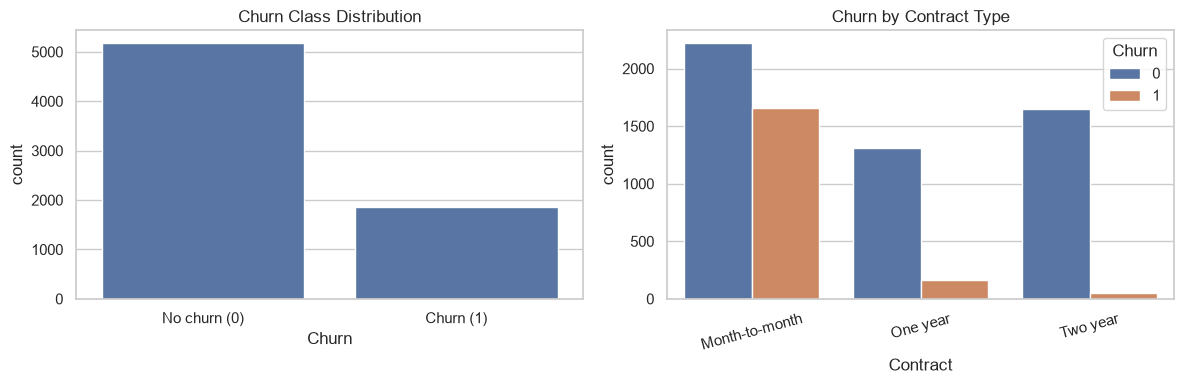

In [5]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
sns.countplot(data=df, x="Churn", ax=axes[0])
axes[0].set_title("Churn Class Distribution")
axes[0].set_xticks([0, 1], ["No churn (0)", "Churn (1)"])
sns.countplot(data=df, x="Contract", hue="Churn", ax=axes[1])
axes[1].set_title("Churn by Contract Type")
axes[1].tick_params(axis="x", rotation=15)
plt.tight_layout()
plt.show()

## 6. Split features and target

In [6]:
X = df.drop(columns=["Churn"])
y = df["Churn"]

numeric_features = X.select_dtypes(include=np.number).columns.tolist()
categorical_features = X.select_dtypes(exclude=np.number).columns.tolist()

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, stratify=y, random_state=RANDOM_STATE
)
print("Train shape:", X_train.shape)
print("Test shape:", X_test.shape)
print("Train churn rate:", round(y_train.mean(), 3))
print("Test churn rate:", round(y_test.mean(), 3))
print("Numeric features:", numeric_features)
print("Categorical features:", categorical_features)

Train shape: (5634, 19)
Test shape: (1409, 19)
Train churn rate: 0.265
Test churn rate: 0.265
Numeric features: ['SeniorCitizen', 'tenure', 'MonthlyCharges', 'TotalCharges']
Categorical features: ['gender', 'Partner', 'Dependents', 'PhoneService', 'MultipleLines', 'InternetService', 'OnlineSecurity', 'OnlineBackup', 'DeviceProtection', 'TechSupport', 'StreamingTV', 'StreamingMovies', 'Contract', 'PaperlessBilling', 'PaymentMethod']


## 7. Build preprocessing pipeline

Numeric columns are median-imputed and standardized. Categorical columns are imputed with the most frequent value and one-hot encoded. Preprocessing is fitted within each training fold, avoiding leakage. For imbalance, we use class weighting/sample weights rather than applying SMOTE before splitting.

In [7]:
numeric_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler())
])
categorical_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("onehot", OneHotEncoder(handle_unknown="ignore"))
])
preprocessor = ColumnTransformer([
    ("num", numeric_pipeline, numeric_features),
    ("cat", categorical_pipeline, categorical_features)
], remainder="drop")

## 8. Train Random Forest and XGBoost with cross-validation

In [8]:
# Random Forest class_weight balances minority-class errors.
rf_pipeline = Pipeline([
    ("preprocessor", preprocessor),
    ("model", RandomForestClassifier(
        n_estimators=400,
        min_samples_leaf=2,
        class_weight="balanced",
        random_state=RANDOM_STATE,
        n_jobs=-1
    ))
])

# scale_pos_weight uses the negative/positive ratio from training data only.
negative_count = int((y_train == 0).sum())
positive_count = int((y_train == 1).sum())
scale_pos_weight = negative_count / max(positive_count, 1)

xgb_pipeline = Pipeline([
    ("preprocessor", preprocessor),
    ("model", XGBClassifier(
        n_estimators=400,
        max_depth=4,
        learning_rate=0.04,
        subsample=0.85,
        colsample_bytree=0.85,
        reg_lambda=1.0,
        objective="binary:logistic",
        eval_metric="logloss",
        scale_pos_weight=scale_pos_weight,
        random_state=RANDOM_STATE,
        n_jobs=-1
    ))
])

cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)
models = {"Random Forest": rf_pipeline, "XGBoost": xgb_pipeline}
cv_results = {}

for name, model in models.items():
    scores = cross_val_score(model, X_train, y_train, cv=cv, scoring="roc_auc", n_jobs=1)
    cv_results[name] = scores
    print(f"{name} CV ROC-AUC: {scores.mean():.4f} ± {scores.std():.4f}")

Random Forest CV ROC-AUC: 0.8378 ± 0.0089
XGBoost CV ROC-AUC: 0.8435 ± 0.0103


## 9. Fit on training data and evaluate on held-out test set

In [9]:
fitted_models = {}
test_predictions = {}
test_probabilities = {}
rows = []

for name, model in models.items():
    model.fit(X_train, y_train)
    fitted_models[name] = model
    pred = model.predict(X_test)
    prob = model.predict_proba(X_test)[:, 1]
    test_predictions[name] = pred
    test_probabilities[name] = prob
    rows.append({
        "Model": name,
        "ROC-AUC": roc_auc_score(y_test, prob),
        "Accuracy": accuracy_score(y_test, pred),
        "Precision": precision_score(y_test, pred, zero_division=0),
        "Recall": recall_score(y_test, pred, zero_division=0),
        "F1-score": f1_score(y_test, pred, zero_division=0)
    })

results_df = pd.DataFrame(rows).set_index("Model").sort_values("ROC-AUC", ascending=False)
display(results_df.style.format("{:.4f}"))
print("Target requirement: ROC-AUC > 0.80. Check the actual held-out test results above.")

,ROC-AUC,Accuracy,Precision,Recall,F1-score
Model,,,,,
XGBoost,0.8397,0.7573,0.5291,0.7781,0.6299
Random Forest,0.8353,0.7594,0.5355,0.7059,0.6090


Target requirement: ROC-AUC > 0.80. Check the actual held-out test results above.


## 10. Plot ROC curves

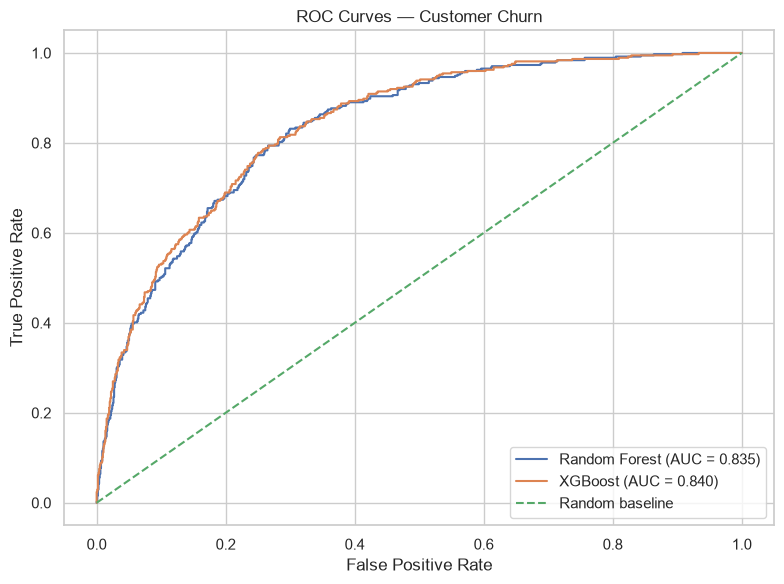

In [10]:
plt.figure(figsize=(8, 6))
for name, prob in test_probabilities.items():
    fpr, tpr, _ = roc_curve(y_test, prob)
    auc_value = roc_auc_score(y_test, prob)
    plt.plot(fpr, tpr, label=f"{name} (AUC = {auc_value:.3f})")
plt.plot([0, 1], [0, 1], linestyle="--", label="Random baseline")
plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("ROC Curves — Customer Churn")
plt.legend(loc="lower right")
plt.tight_layout()
plt.show()

## 11. Confusion matrices and classification reports

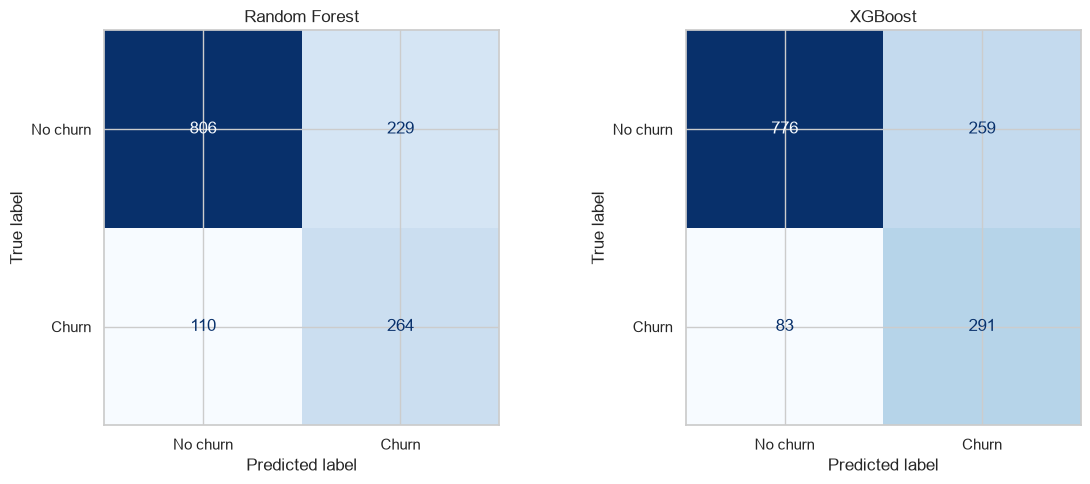

Random Forest
              precision    recall  f1-score   support

    No churn       0.88      0.78      0.83      1035
       Churn       0.54      0.71      0.61       374

    accuracy                           0.76      1409
   macro avg       0.71      0.74      0.72      1409
weighted avg       0.79      0.76      0.77      1409

XGBoost
              precision    recall  f1-score   support

    No churn       0.90      0.75      0.82      1035
       Churn       0.53      0.78      0.63       374

    accuracy                           0.76      1409
   macro avg       0.72      0.76      0.72      1409
weighted avg       0.80      0.76      0.77      1409



In [11]:
fig, axes = plt.subplots(1, len(fitted_models), figsize=(12, 5))
if len(fitted_models) == 1:
    axes = [axes]
for ax, (name, pred) in zip(axes, test_predictions.items()):
    cm = confusion_matrix(y_test, pred, labels=[0, 1])
    disp = ConfusionMatrixDisplay(cm, display_labels=["No churn", "Churn"])
    disp.plot(ax=ax, cmap="Blues", colorbar=False)
    ax.set_title(name)
plt.tight_layout()
plt.show()

for name, pred in test_predictions.items():
    print("=" * 60)
    print(name)
    print(classification_report(y_test, pred, target_names=["No churn", "Churn"], zero_division=0))

## 12. Top 10 feature importances

,Feature,Importance
36,cat__Contract_Month-to-month,0.374515
16,cat__InternetService_Fiber optic,0.088520
18,cat__OnlineSecurity_No,0.080334
38,cat__Contract_Two year,0.039810
27,cat__TechSupport_No,0.029445
35,cat__StreamingMovies_Yes,0.028706
15,cat__InternetService_DSL,0.026513
37,cat__Contract_One year,0.025317
17,cat__InternetService_No,0.025241
43,cat__PaymentMethod_Electronic check,0.019992


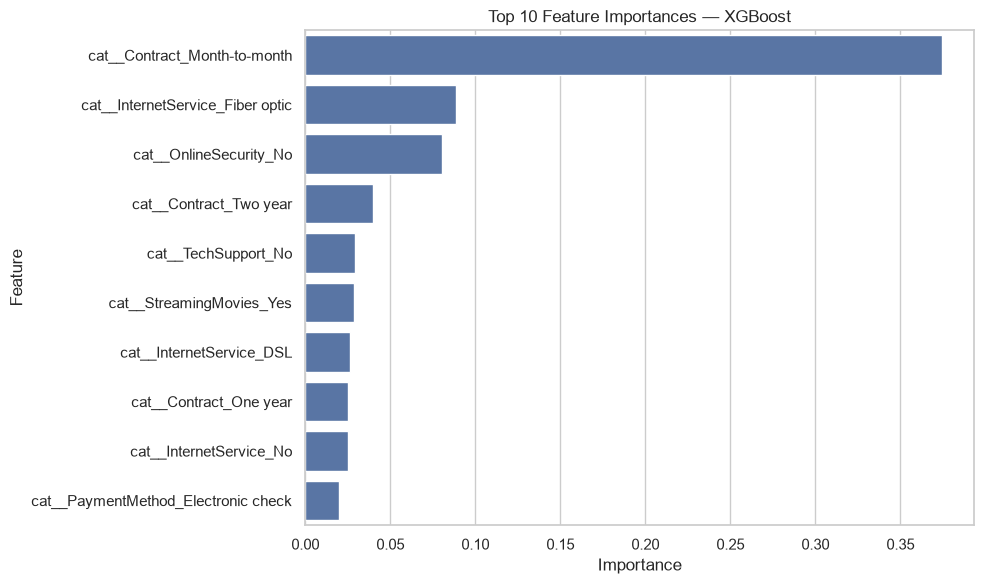

In [12]:
# Feature names after one-hot encoding.
best_model_name = results_df.index[0]
best_pipeline = fitted_models[best_model_name]
fitted_preprocessor = best_pipeline.named_steps["preprocessor"]
feature_names = fitted_preprocessor.get_feature_names_out()
estimator = best_pipeline.named_steps["model"]

if hasattr(estimator, "feature_importances_"):
    importances = estimator.feature_importances_
    importance_df = pd.DataFrame({
        "Feature": feature_names,
        "Importance": importances
    }).sort_values("Importance", ascending=False).head(10)

    display(importance_df)
    plt.figure(figsize=(10, 6))
    sns.barplot(data=importance_df, x="Importance", y="Feature")
    plt.title(f"Top 10 Feature Importances — {best_model_name}")
    plt.tight_layout()
    plt.show()
else:
    print("Selected estimator does not expose feature_importances_.")

## 13. Compare cross-validation ROC-AUC


,Mean CV ROC-AUC,Std CV ROC-AUC
Random Forest,0.8378,0.0089
XGBoost,0.8435,0.0103


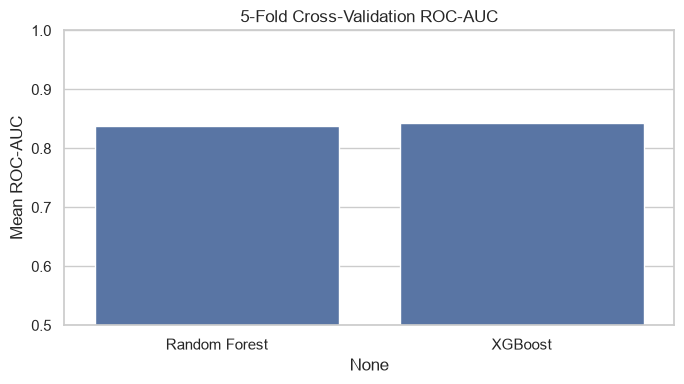

In [13]:
cv_summary = pd.DataFrame({
    name: {
        "Mean CV ROC-AUC": scores.mean(),
        "Std CV ROC-AUC": scores.std()
    }
    for name, scores in cv_results.items()
}).T
display(cv_summary.round(4))

plt.figure(figsize=(7, 4))
sns.barplot(x=cv_summary.index, y=cv_summary["Mean CV ROC-AUC"])
plt.ylim(0.5, 1.0)
plt.ylabel("Mean ROC-AUC")
plt.title("5-Fold Cross-Validation ROC-AUC")
plt.tight_layout()
plt.show()

## 14. Conclusion and reporting checklist

Use the executed results to identify the stronger model. ROC-AUC measures ranking ability across thresholds; it does not choose an operational threshold by itself. For churn campaigns, inspect recall and precision alongside ROC-AUC because false negatives and false positives have different business costs.

- Report held-out test ROC-AUC and cross-validation mean/std.
- Include the ROC curve and confusion matrix in the repository.
- Explain how class imbalance was handled (`class_weight="balanced"` for Random Forest and `scale_pos_weight` for XGBoost).
- Avoid claiming ROC-AUC > 0.80 unless the measured test score supports it.
- Feature importance is model-specific and indicates predictive contribution, not causality.

### Suggested GitHub repository structure
```text
datheon-task-3-customer-churn/
├── customer_churn_classifier.ipynb
├── README.md
└── requirements.txt
```
